# DGS3MO yield and cash return

The risk-free leg: 3-month Treasury constant-maturity yield from FRED, converted to a daily simple cash return `(1 + y)^(1/252) - 1` and lagged one day so `rf[t]` only uses information available at t-1 (no look-ahead). Run from the `notebooks/` folder.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

COLORS = {"blue": "#2a78d6", "orange": "#eb6834", "ink": "#0b0b0b",
          "muted": "#898781", "grid": "#e1e0d9"}
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["grid"], "grid.linewidth": 0.8,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": COLORS["muted"],
    "xtick.color": COLORS["muted"], "ytick.color": COLORS["muted"],
    "text.color": COLORS["ink"], "axes.titlecolor": COLORS["ink"],
    "axes.prop_cycle": plt.cycler(color=[COLORS["blue"], COLORS["orange"]]),
})

import json

df = pd.read_parquet(Path("../data/cache/spy_dataset.parquet"))
manifest = json.loads(Path("../data/snapshots/snapshot_manifest.json").read_text())
fred_name = next(n for n in manifest["files"] if n.startswith("dgs3mo"))
raw = pd.read_csv(Path("../data/snapshots") / fred_name, na_values=".")
yields = pd.Series(raw.iloc[:, 1].to_numpy(float),
                   index=pd.DatetimeIndex(pd.to_datetime(raw.iloc[:, 0]))).dropna()
yields.tail()

observation_date
2026-06-24    3.85
2026-06-25    3.84
2026-06-26    3.83
2026-06-29    3.87
2026-06-30    3.87
dtype: float64

## Yield history

The full rate cycle: dot-com easing, the 2004-06 hikes, ZIRP after 2008, the 2015-18 normalization, COVID zero, the 2022 hikes.

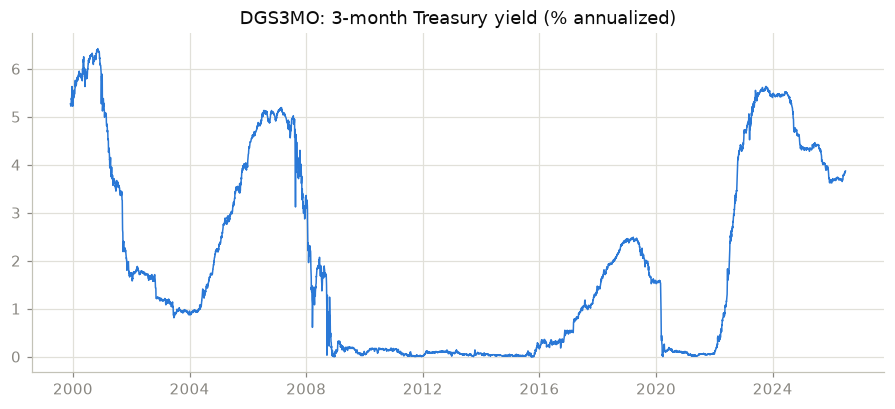

In [2]:
fig, ax = plt.subplots()
ax.plot(yields.index, yields, lw=1)
ax.set_title("DGS3MO: 3-month Treasury yield (% annualized)")
plt.show()

## Daily cash return

`rf` is what one dollar of cash earns over each trading day. Annualizing it back should trace the quoted yield (with the one-day lag).

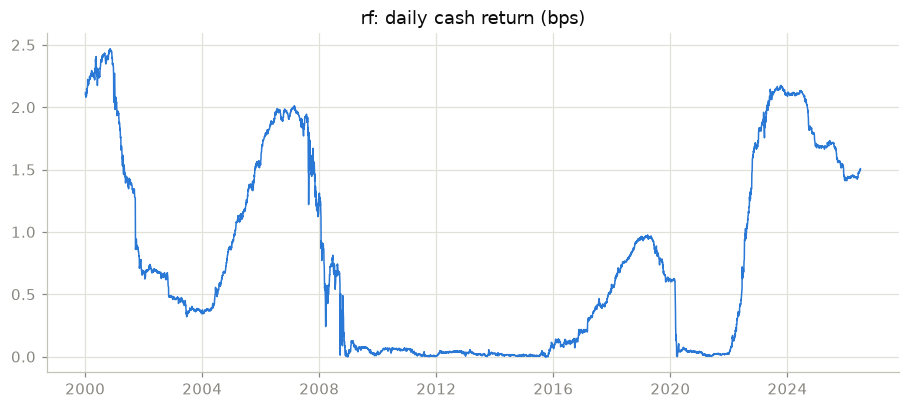

In [3]:
fig, ax = plt.subplots()
ax.plot(df.index, df["rf"] * 1e4, lw=1)
ax.set_title("rf: daily cash return (bps)")
plt.show()

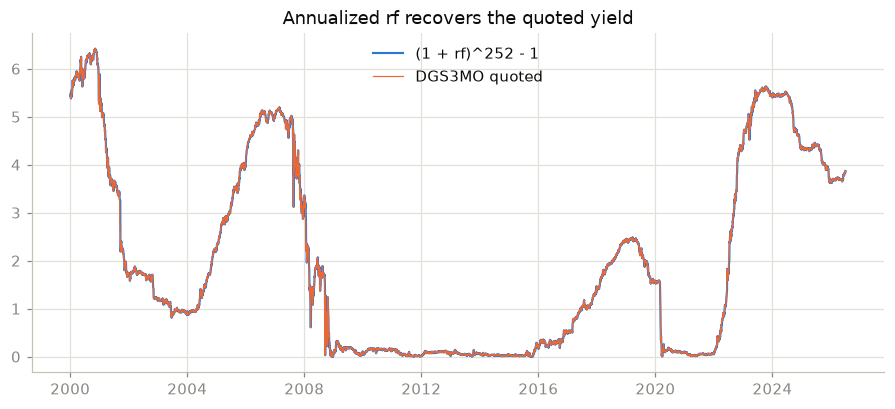

In [4]:
implied = ((1 + df["rf"]) ** 252 - 1) * 100
fig, ax = plt.subplots()
ax.plot(implied.index, implied, label="(1 + rf)^252 - 1", lw=1.4)
ax.plot(yields.loc[df.index[0]:].index, yields.loc[df.index[0]:],
        label="DGS3MO quoted", lw=0.8)
ax.set_title("Annualized rf recovers the quoted yield")
ax.legend(frameon=False)
plt.show()

## Missing observations

DGS3MO follows the bond-market calendar; the NYSE trades on Columbus Day and Veterans Day when no yield is published. Those days are forward-filled from the previous business day.

In [5]:
missing = df.index[~df.index.isin(yields.index)]
label = missing.to_series().apply(
    lambda d: "Columbus Day" if (d.month == 10 and 8 <= d.day <= 14 and d.dayofweek == 0)
    else "Veterans Day" if (d.month == 11 and 10 <= d.day <= 12) else "other")
print(f"{len(missing)} NYSE trading days without a DGS3MO print (forward-filled)")
label.value_counts()

48 NYSE trading days without a DGS3MO print (forward-filled)


date
Columbus Day    26
Veterans Day    22
Name: count, dtype: int64

## No look-ahead check

`rf[t]` must equal the transform of the last yield available strictly before t.

In [6]:
for t in [df.index[1], pd.Timestamp("2008-09-16"), pd.Timestamp("2020-03-17"), df.index[-1]]:
    prev = df.index[df.index.get_loc(t) - 1]
    y_prev = yields.loc[:prev].iloc[-1]
    assert abs(df.loc[t, "rf"] - ((1 + y_prev / 100) ** (1 / 252) - 1)) < 1e-15
    print(f"{t.date()}: rf uses yield from {yields.loc[:prev].index[-1].date()} ({y_prev:.2f}%)")

2000-01-05: rf uses yield from 2000-01-04 (5.43%)
2008-09-16: rf uses yield from 2008-09-15 (1.02%)
2020-03-17: rf uses yield from 2020-03-16 (0.24%)
2026-06-30: rf uses yield from 2026-06-29 (3.87%)


## Cash over the sample

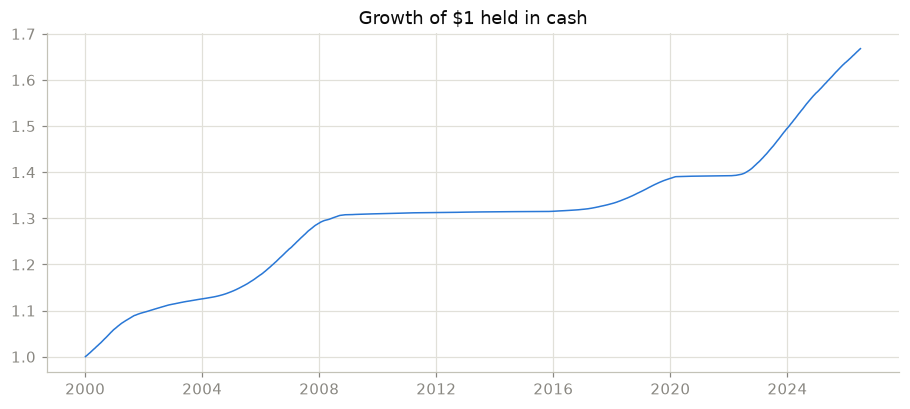

$1 in 2000 -> $1.67 by 2026-06-30


In [7]:
growth = (1 + df["rf"]).cumprod()
fig, ax = plt.subplots()
ax.plot(growth.index, growth, lw=1)
ax.set_title("Growth of $1 held in cash")
plt.show()
print(f"$1 in 2000 -> ${growth.iloc[-1]:.2f} by {growth.index[-1].date()}")